<a href="https://colab.research.google.com/github/20deepak28/Customer-Lifetime-Value-Churn-Intelligence/blob/main/05_shap_model_explainability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## SHAP
#### SHAP stands for SHapley Additive exPlanations.
#### It's a technique used in Machine Learning to explain why a model makes a particular prediction.
SHAP calculates how much each feature contributes to a model's prediction.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install shap

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib
import os

sns.set_theme(style="whitegrid")

In [ ]:
project_path = '/content/drive/MyDrive/Customer-Lifetime-Value-Churn-Intelligence'

data_path = os.path.join(project_path, 'data')
model_path = os.path.join(
    project_path,
    'models',
    'final_logistic_regression.pkl'
)

df = pd.read_csv(
    os.path.join(data_path, 'telco_churn_feature_engineered.csv')
)

print("Dataset shape:", df.shape)
print("Model file exists:", os.path.exists(model_path))

Dataset shape: (7043, 22)
Model file exists: True


### Load the trained model

In [ ]:
model = joblib.load(model_path)

print("Model loaded successfully!")
print(model)

Model loaded successfully!
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges',
                                                   'AdditionalServicesCount']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup

### Separate features and target

In [ ]:
X = df.drop(columns=['Churn'])
y = df['Churn'].map({'No': 0, 'Yes': 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 21)
Target shape: (7043,)


### Verify the model pipeline

In [ ]:
print("Pipeline steps:")
print(model.named_steps.keys())

Pipeline steps:
dict_keys(['preprocessor', 'classifier'])


## Preprocessor, Classifier & Pipeline

### 1. Preprocessor
- Prepares raw data before giving it to the ML model.
- Converts categorical (text) data into numerical data using **OneHotEncoder**.
- Scales numerical features using **StandardScaler**.
- Makes data suitable for machine learning.

### 2. Classifier
- The actual machine learning algorithm that makes predictions.
- In our project, we use **Logistic Regression**.
- Predicts the probability of a customer churning.

### 3. Pipeline
- Connects the preprocessor and classifier.
- Automatically prepares the data and makes predictions.

```text
Raw Customer Data
       ↓
  Preprocessor
       ↓
Numerical Data
       ↓
   Classifier
       ↓
 Churn Prediction
```

### 4. Transformation
- Transformation means applying preprocessing steps to raw data.
- `preprocessor.transform(X)` converts our original dataset into the numerical format required by the classifier.
- It does not train a new model or modify the original dataset.

**Remember:**
- Preprocessor = Prepares data.
- Classifier = Makes predictions.
- Pipeline = Connects both.
- Transformation = Converts data into model-ready format.

### Transform the dataset

In [ ]:
preprocessor = model.named_steps['preprocessor']

X_transformed = preprocessor.transform(X)

print("Original shape:", X.shape)
print("Transformed shape:", X_transformed.shape)

Original shape: (7043, 21)
Transformed shape: (7043, 50)


### Extract features names

In [ ]:
feature_names = preprocessor.get_feature_names_out()

print("Total transformed features:", len(feature_names))

print(feature_names)

Total transformed features: 50
['num__SeniorCitizen' 'num__tenure' 'num__MonthlyCharges'
 'num__TotalCharges' 'num__AdditionalServicesCount' 'cat__gender_Female'
 'cat__gender_Male' 'cat__Partner_No' 'cat__Partner_Yes'
 'cat__Dependents_No' 'cat__Dependents_Yes' 'cat__PhoneService_No'
 'cat__PhoneService_Yes' 'cat__MultipleLines_No'
 'cat__MultipleLines_No phone service' 'cat__MultipleLines_Yes'
 'cat__InternetService_DSL' 'cat__InternetService_Fiber optic'
 'cat__InternetService_No' 'cat__OnlineSecurity_No'
 'cat__OnlineSecurity_No internet service' 'cat__OnlineSecurity_Yes'
 'cat__OnlineBackup_No' 'cat__OnlineBackup_No internet service'
 'cat__OnlineBackup_Yes' 'cat__DeviceProtection_No'
 'cat__DeviceProtection_No internet service' 'cat__DeviceProtection_Yes'
 'cat__TechSupport_No' 'cat__TechSupport_No internet service'
 'cat__TechSupport_Yes' 'cat__StreamingTV_No'
 'cat__StreamingTV_No internet service' 'cat__StreamingTV_Yes'
 'cat__StreamingMovies_No' 'cat__StreamingMovies_No inter

### Convert transformed data into a dataframe

In [ ]:
X_transformed_df = pd.DataFrame(
    X_transformed,
    columns=feature_names,
    index=X.index
)

X_transformed_df.head()

,num__SeniorCitizen,num__tenure,num__MonthlyCharges,num__TotalCharges,num__AdditionalServicesCount,cat__gender_Female,cat__gender_Male,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,...,cat__PaperlessBilling_No,cat__PaperlessBilling_Yes,cat__PaymentMethod_Bank transfer (automatic),cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check,cat__TenureGroup_Developing,cat__TenureGroup_Established,cat__TenureGroup_Loyal,cat__TenureGroup_New
0,-0.439271,-1.269426,-1.160949,-0.988792,-0.567221,1.0,0.0,0.0,1.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1,-0.439271,0.069099,-0.258053,-0.172721,-0.026971,0.0,1.0,1.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2,-0.439271,-1.228865,-0.361336,-0.954432,-0.026971,0.0,1.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,-0.439271,0.515274,-0.746150,-0.194114,0.513280,0.0,1.0,1.0,0.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,-0.439271,-1.228865,0.200058,-0.935343,-1.107472,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


### Prepare Data for SHAP

In [ ]:
# Convert transformed data into a DataFrame
X_transformed_df = pd.DataFrame(
    X_transformed,
    columns=feature_names,
    index=X.index
)

print("Shape:", X_transformed_df.shape)

X_transformed_df.head()

Shape: (7043, 50)


,num__SeniorCitizen,num__tenure,num__MonthlyCharges,num__TotalCharges,num__AdditionalServicesCount,cat__gender_Female,cat__gender_Male,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,...,cat__PaperlessBilling_No,cat__PaperlessBilling_Yes,cat__PaymentMethod_Bank transfer (automatic),cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check,cat__TenureGroup_Developing,cat__TenureGroup_Established,cat__TenureGroup_Loyal,cat__TenureGroup_New
0,-0.439271,-1.269426,-1.160949,-0.988792,-0.567221,1.0,0.0,0.0,1.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1,-0.439271,0.069099,-0.258053,-0.172721,-0.026971,0.0,1.0,1.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2,-0.439271,-1.228865,-0.361336,-0.954432,-0.026971,0.0,1.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,-0.439271,0.515274,-0.746150,-0.194114,0.513280,0.0,1.0,1.0,0.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,-0.439271,-1.228865,0.200058,-0.935343,-1.107472,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


### Create SHAP Explainer

In [ ]:
# Extract Logistic Regression classifier
classifier = model.named_steps['classifier']

print(classifier)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)


### For Entire dataset

In [ ]:
# Use the entire transformed dataset as background
background = X_transformed_df

# Create SHAP explainer
explainer = shap.LinearExplainer(
    classifier,
    background
)

# Calculate SHAP values for all 7,043 customers
shap_values = explainer(X_transformed_df)

print("SHAP analysis completed!")
print("Customers explained:", shap_values.shape[0])
print("Features explained:", shap_values.shape[1])

SHAP analysis completed!
Customers explained: 7043
Features explained: 50


### Gloabal Feature Importace

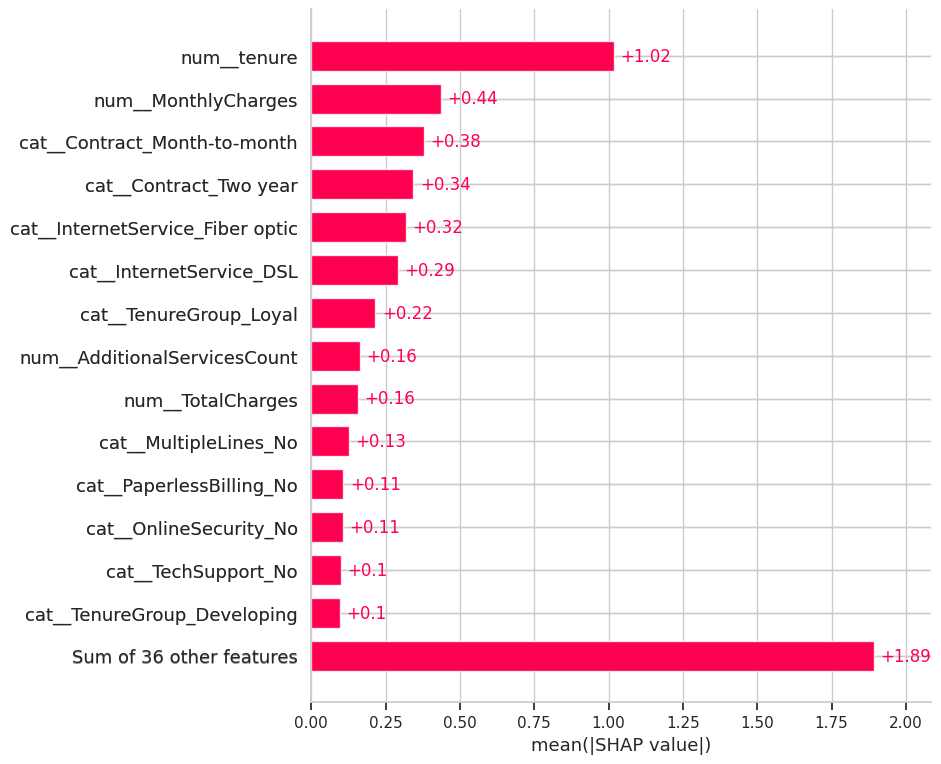

In [ ]:
shap.plots.bar(shap_values, max_display=15)

### SHAP Beeswarm Plot
This visualization will show:
- Which features increase churn predictions.
- Which features decrease churn predictions.
- How high and low feature values influence predictions.

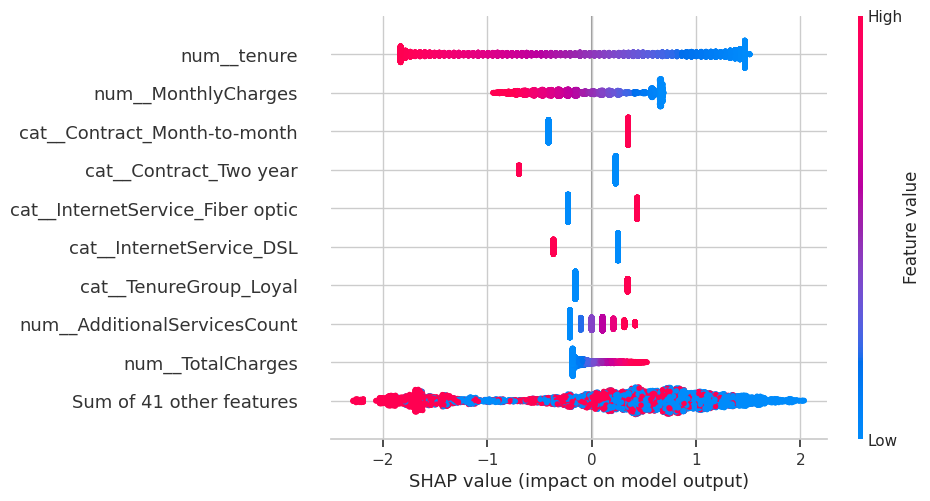

In [ ]:
shap.plots.beeswarm(shap_values, max_display=10)

### INdividual Customer Explaination

- Which features increased their churn prediction?
- Which features decreased it?
- What was the final model output?

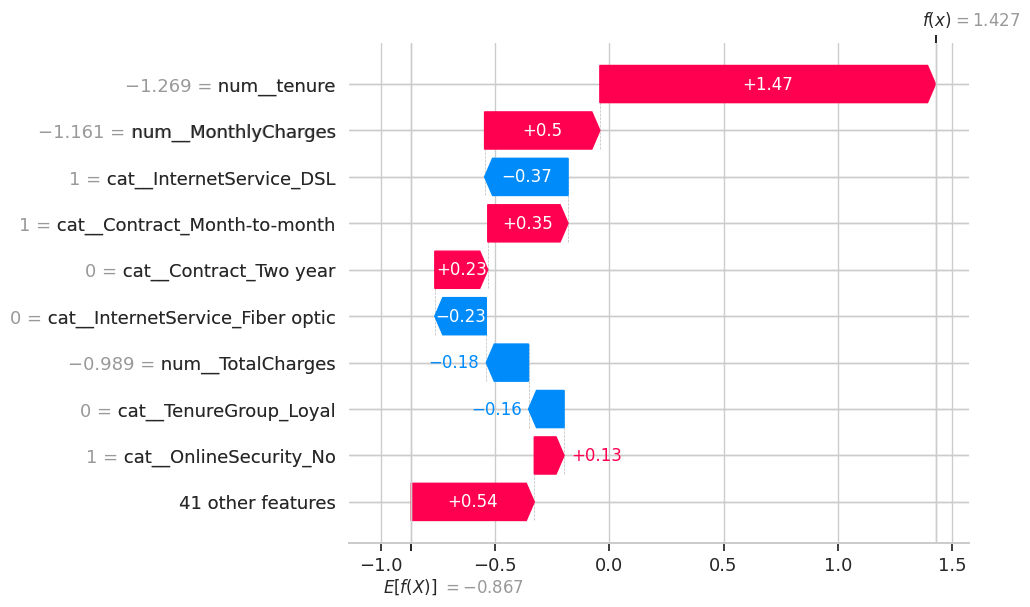

In [ ]:
shap.plots.waterfall(shap_values[0])

### Save SHAP Explainabilty Results

In [ ]:
import os
import matplotlib.pyplot as plt

# Create folder
figures_path = os.path.join(
    project_path, 'documentation', 'figures'
)
os.makedirs(figures_path, exist_ok=True)

# 1. SHAP Global Feature Importance
shap.plots.bar(shap_values, max_display=20, show=False)
plt.savefig(
    os.path.join(figures_path, 'shap_global_importance.png'),
    dpi=300, bbox_inches='tight'
)
plt.close()

# 2. SHAP Beeswarm Plot
shap.plots.beeswarm(shap_values, max_display=20, show=False)
plt.savefig(
    os.path.join(figures_path, 'shap_beeswarm.png'),
    dpi=300, bbox_inches='tight'
)
plt.close()

# 3. SHAP Waterfall Plot
shap.plots.waterfall(shap_values[0], show=False)
plt.savefig(
    os.path.join(figures_path, 'shap_customer_waterfall.png'),
    dpi=300, bbox_inches='tight'
)
plt.close()

print("All SHAP visualizations saved successfully!")

print(os.listdir(figures_path))

All SHAP visualizations saved successfully!
['shap_global_importance.png', 'shap_beeswarm.png', 'shap_customer_waterfall.png']


In [ ]:
import numpy as np

np.savez_compressed(
    os.path.join(project_path, 'models', 'shap_values.npz'),
    values=shap_values.values,
    base_values=shap_values.base_values,
    data=shap_values.data,
    feature_names=shap_values.feature_names
)

print("SHAP values saved successfully!")

SHAP values saved successfully!
